# 🏠 Airbnb NYC Price Prediction

## Notebook: Data Understanding, Data Cleaning & EDA

### Purpose of This Notebook
This notebook covers the first three stages of the data science pipeline:
1. **Data Understanding** — Explore raw dataset structure, column meanings, data types
2. **Data Cleaning** — Handle missing values, duplicates, outliers, incorrect data types
3. **Exploratory Data Analysis (EDA)** — Visualize patterns, distributions, and relationships 
   in the data to generate insights before modeling

### Dataset
- **Source:** [NYC Airbnb Open Data - Kaggle](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)
- **File:** AB_NYC_2019.csv
- **Rows:** ~48,895
- **Columns:** 16
- **Target Variable (for later modeling):** `price`

### Column Description
| Column | Description |
|---|---|
| id | Unique listing ID |
| name | Listing title |
| host_id | Unique host ID |
| host_name | Host's name |
| neighbourhood_group | Borough (Manhattan, Brooklyn, etc.) |
| neighbourhood | Specific neighbourhood |
| latitude, longitude | Geographic coordinates |
| room_type | Entire home/apt, Private room, Shared room |
| price | Nightly price (USD) |
| minimum_nights | Minimum nights required |
| number_of_reviews | Total reviews received |
| last_review | Date of most recent review |
| reviews_per_month | Average reviews per month |
| calculated_host_listings_count | Number of listings by host |
| availability_365 | Days available per year |



### Author
**Shailesh Pawar**  
🔗 LinkedIn: [ShaileshPawar-CSE](https://www.linkedin.com/in/ShaileshPawar-CSE)  
🔗 GitHub: [Shailesh-Pawar-18](https://github.com/Shailesh-Pawar-18)

---

# 1. Data Understanding

In [3]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [4]:
# Load Dataset
df = pd.read_csv("AB_NYC_2019.csv")
print("Dataset Loaded Successfully")
print("Shape:", df.shape)

Dataset Loaded Successfully
Shape: (48895, 16)


In [5]:
print("Shape (rows, columns):", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Shape (rows, columns): (48895, 16)

Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [7]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [8]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [9]:
df.describe(include='object')

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
count,48879,48874,48895,48895,48895,38843
unique,47905,11452,5,221,3,1764
top,Hillside Hotel,Michael,Manhattan,Williamsburg,Entire home/apt,2019-06-23
freq,18,417,21661,3920,25409,1413


## 📋 Data Understanding — Key Findings

### Dataset Size
- 48,895 rows × 16 columns

### Missing Values Identified
| Column | Missing Count | Missing % |
|---|---|---|
| name | 16 | 0.03% |
| host_name | 21 | 0.04% |
| last_review | 10,052 | 20.6% |
| reviews_per_month | 10,052 | 20.6% |

**Insight:** `last_review` and `reviews_per_month` have the same missing count (10,052) — 
likely these are listings that have **never received a review**, not random missing data.

### Data Type Issues
- `last_review` is stored as `object` (text) — should be converted to `datetime`

### Outliers / Suspicious Values (from describe())
| Column | Issue |
|---|---|
| `price` | Min = $0 (invalid, a listing can't be free) — Max = $10,000 (extreme outlier) |
| `minimum_nights` | Max = 1250 nights (~3.4 years) — likely data entry error or inactive listing |
| `calculated_host_listings_count` | Max = 327 listings by one host — unusual but could be legitimate (property management company) |

### Categorical Columns Overview
- `neighbourhood_group`: 5 unique values (boroughs) — Manhattan has the most listings (21,661)
- `room_type`: 3 unique values — "Entire home/apt" is most common (25,409 listings)
- `neighbourhood`: 221 unique values — high cardinality, may need grouping/encoding strategy later

### Columns Likely Not Useful for Modeling (to address in cleaning)
- `id`, `host_id` — unique identifiers, not predictive features
- `name`, `host_name` — free text, not directly usable without NLP (out of scope here)

### Next Steps (Data Cleaning)


In [11]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


### Duplicate Check
- **Total duplicate rows: 0** — No duplicate records found in the dataset.

---

## ✅ Data Understanding — Complete

We now move to **Data Cleaning**, addressing the issues identified above.

## 🧹 Data Cleaning

This section addresses the issues identified during Data Understanding:
1. Handle missing values
2. Fix data types
3. Handle outliers
4. Remove irrelevant columns (for modeling purposes, kept in a working copy)

In [14]:
# Column: id
print("Data type:", df['id'].dtype)
print("Missing values:", df['id'].isnull().sum())
print("Unique values:", df['id'].nunique())
print("Total rows:", len(df))

Data type: int64
Missing values: 0
Unique values: 48895
Total rows: 48895


### Column: `id`
- Data type: int64 ✅
- Missing values: 0 ✅
- Unique values: 48,895 (matches total rows) ✅
- **Conclusion:** No cleaning needed. Valid unique identifier.

In [16]:
# Column: name
print("Data type:", df['name'].dtype)
print("Missing values:", df['name'].isnull().sum())
print("Unique values:", df['name'].nunique())
print("\nSample values:")
print(df['name'].head(10))

Data type: object
Missing values: 16
Unique values: 47905

Sample values:
0                  Clean & quiet apt home by the park
1                               Skylit Midtown Castle
2                 THE VILLAGE OF HARLEM....NEW YORK !
3                     Cozy Entire Floor of Brownstone
4    Entire Apt: Spacious Studio/Loft by central park
5           Large Cozy 1 BR Apartment In Midtown East
6                                     BlissArtsSpace!
7                    Large Furnished Room Near B'way 
8                  Cozy Clean Guest Room - Family Apt
9                  Cute & Cozy Lower East Side 1 bdrm
Name: name, dtype: object


In [17]:
# Fill missing names with placeholder
df['name'] = df['name'].fillna("Unknown")

# Verify fix
print("Missing values after fix:", df['name'].isnull().sum())

Missing values after fix: 0


### Column: `name`
- Data type: object (text) 
- Missing values: 16 → **Fixed** (filled with "Unknown")
- Unique values: 47,905 (high cardinality, free text listing titles)
- **Conclusion:** Not useful as a direct ML feature without NLP processing (out of scope for this project). Missing values handled for data completeness.

In [19]:
# Column: host_id
print("Data type:", df['host_id'].dtype)
print("Missing values:", df['host_id'].isnull().sum())
print("Unique values:", df['host_id'].nunique())
print("Total rows:", len(df))

Data type: int64
Missing values: 0
Unique values: 37457
Total rows: 48895


### Column: `host_id`
- Data type: int64 ✅
- Missing values: 0 ✅
- Unique values: 37,457 (fewer than total rows — expected, since one host can own multiple listings)
- **Conclusion:** No cleaning needed. Valid identifier, confirms many hosts manage multiple properties.

In [21]:
# Column: host_name
print("Data type:", df['host_name'].dtype)
print("Missing values:", df['host_name'].isnull().sum())
print("Unique values:", df['host_name'].nunique())
print("\nSample values:")
print(df['host_name'].head(10))

Data type: object
Missing values: 21
Unique values: 11452

Sample values:
0           John
1       Jennifer
2      Elisabeth
3    LisaRoxanne
4          Laura
5          Chris
6          Garon
7       Shunichi
8      MaryEllen
9            Ben
Name: host_name, dtype: object


In [22]:
# Fill missing host_name with placeholder
df['host_name'] = df['host_name'].fillna("Unknown")

# Verify fix
print("Missing values after fix:", df['host_name'].isnull().sum())

Missing values after fix: 0


### Column: `host_name`
- Data type: object (text)
- Missing values: 21 → **Fixed** (filled with "Unknown")
- Unique values: 11,452
- **Conclusion:** Not a direct predictive feature for price modeling, but useful for host-level grouping/analysis in SQL/EDA. Missing values handled for completeness.

In [24]:
# Column: neighbourhood_group
print("Data type:", df['neighbourhood_group'].dtype)
print("Missing values:", df['neighbourhood_group'].isnull().sum())
print("Unique values:", df['neighbourhood_group'].nunique())
print("\nValue counts:")
print(df['neighbourhood_group'].value_counts())

Data type: object
Missing values: 0
Unique values: 5

Value counts:
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


### Column: `neighbourhood_group`
- Data type: object ✅
- Missing values: 0 ✅
- Unique values: 5 (Manhattan, Brooklyn, Queens, Bronx, Staten Island)
- **Distribution:** Manhattan (21,661) and Brooklyn (20,104) dominate; Staten Island has fewest listings (373)
- **Conclusion:** No cleaning needed. Clean categorical column, ready for use in EDA/modeling.

In [26]:
# Column: neighbourhood
print("Data type:", df['neighbourhood'].dtype)
print("Missing values:", df['neighbourhood'].isnull().sum())
print("Unique values:", df['neighbourhood'].nunique())
print("\nTop 10 neighbourhoods by count:")
print(df['neighbourhood'].value_counts().head(10))

Data type: object
Missing values: 0
Unique values: 221

Top 10 neighbourhoods by count:
neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545
Name: count, dtype: int64


### Column: `neighbourhood`
- Data type: object ✅
- Missing values: 0 ✅
- Unique values: 221 (high cardinality)
- **Top neighbourhoods:** Williamsburg (3,920), Bedford-Stuyvesant (3,714), Harlem (2,658)
- **Conclusion:** No cleaning needed now. High cardinality noted — will require careful encoding strategy (e.g., target/frequency encoding, not one-hot) during Feature Engineering stage.

In [28]:
# Column: latitude
print("Data type:", df['latitude'].dtype)
print("Missing values:", df['latitude'].isnull().sum())
print("Min:", df['latitude'].min())
print("Max:", df['latitude'].max())

Data type: float64
Missing values: 0
Min: 40.49979
Max: 40.91306


### Column: `latitude`
- Data type: float64 ✅
- Missing values: 0 ✅
- Range: 40.4998 to 40.9131 — valid NYC latitude range ✅
- **Conclusion:** No cleaning needed. Valid geographic data.

In [30]:
# Column: longitude
print("Data type:", df['longitude'].dtype)
print("Missing values:", df['longitude'].isnull().sum())
print("Min:", df['longitude'].min())
print("Max:", df['longitude'].max())

Data type: float64
Missing values: 0
Min: -74.24442
Max: -73.71299


### Column: `longitude`
- Data type: float64 ✅
- Missing values: 0 ✅
- Range: -74.2444 to -73.7130 — valid NYC longitude range ✅
- **Conclusion:** No cleaning needed. Valid geographic data.

In [32]:
# Column: room_type
print("Data type:", df['room_type'].dtype)
print("Missing values:", df['room_type'].isnull().sum())
print("Unique values:", df['room_type'].nunique())
print("\nValue counts:")
print(df['room_type'].value_counts())

Data type: object
Missing values: 0
Unique values: 3

Value counts:
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


### Column: `room_type`
- Data type: object ✅
- Missing values: 0 ✅
- Unique values: 3 (Entire home/apt, Private room, Shared room)
- **Distribution:** Entire home/apt (25,409), Private room (22,326), Shared room (1,160)
- **Conclusion:** No cleaning needed. Clean categorical column, ready for use in EDA/modeling.

In [34]:
# Column: price
print("Data type:", df['price'].dtype)
print("Missing values:", df['price'].isnull().sum())
print("Min:", df['price'].min())
print("Max:", df['price'].max())
print("\nHow many listings have price = 0?")
print((df['price'] == 0).sum())
print("\nHow many listings have price > 1000?")
print((df['price'] > 1000).sum())

Data type: int64
Missing values: 0
Min: 0
Max: 10000

How many listings have price = 0?
11

How many listings have price > 1000?
239


In [35]:
# Investigate price = 0 listings
df[df['price'] == 0][['id', 'name', 'neighbourhood_group', 'room_type', 'price']]

,id,name,neighbourhood_group,room_type,price
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,Private room,0
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,Private room,0
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,Private room,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Brooklyn,Private room,0
25778,20624541,Modern apartment in the heart of Williamsburg,Brooklyn,Entire home/apt,0
25794,20639628,Spacious comfortable master bedroom with nice ...,Brooklyn,Private room,0
25795,20639792,Contemporary bedroom in brownstone with nice view,Brooklyn,Private room,0
25796,20639914,Cozy yet spacious private brownstone bedroom,Brooklyn,Private room,0
26259,20933849,the best you can find,Manhattan,Entire home/apt,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Brooklyn,Shared room,0


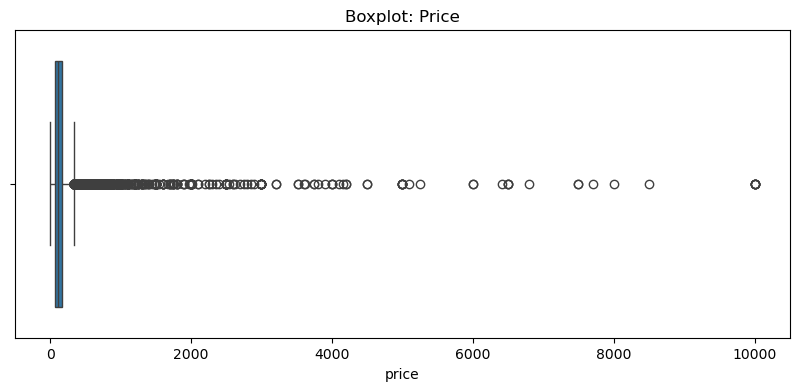

In [36]:
#Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'])
plt.title('Boxplot: Price')
plt.show()

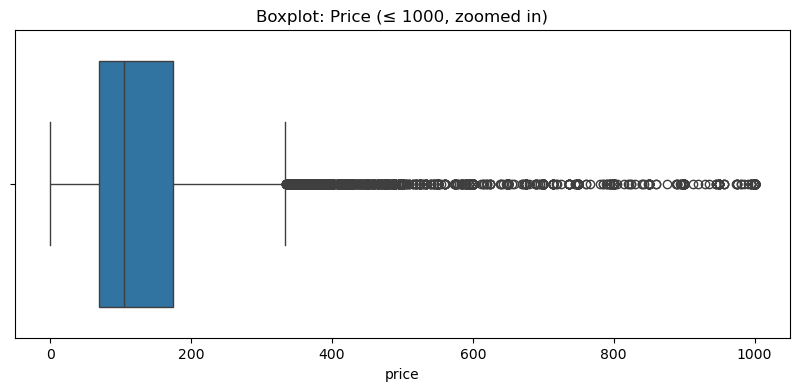

In [37]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[df['price'] <= 1000]['price'])
plt.title('Boxplot: Price (≤ 1000, zoomed in)')
plt.show()

In [38]:
# Check percentile distribution of price
print(df['price'].quantile([0.90, 0.95, 0.99, 0.999]))

0.900     269.0
0.950     355.0
0.990     799.0
0.999    3000.0
Name: price, dtype: float64


In [39]:
# Investigate price >= 3000 listings
df[df['price'] >= 3000][['id', 'name', 'neighbourhood_group', 'room_type', 'price']][:10]

,id,name,neighbourhood_group,room_type,price
946,363673,Beautiful 3 bedroom in Manhattan,Manhattan,Private room,3000
1862,826690,"Sunny, Family-Friendly 2 Bedroom",Brooklyn,Entire home/apt,4000
2698,1448703,Beautiful 1 Bedroom in Nolita/Soho,Manhattan,Entire home/apt,5000
3537,2110145,UWS 1BR w/backyard + block from CP,Manhattan,Entire home/apt,6000
3695,2224896,NYC SuperBowl Wk 5 Bdrs River View,Manhattan,Entire home/apt,4000
3720,2243699,"SuperBowl Penthouse Loft 3,000 sqft",Manhattan,Entire home/apt,5250
3774,2271504,SUPER BOWL Brooklyn Duplex Apt!!,Brooklyn,Entire home/apt,6500
3788,2281142,Prime NYC Location for Super Bowl,Manhattan,Entire home/apt,3750
4345,2919330,NearWilliamsburg bridge 11211 BK,Brooklyn,Private room,5000
4376,2952861,Photography Location,Brooklyn,Entire home/apt,4500


### Column: `price` (Target Variable) 

**Findings so far:**
- 11 listings with price = $0 (invalid)
  
- 239 listings with price > $1,000 (extreme outliers)

- 99th percentile = $799, Max = $10,000

In [41]:
# Remove logically invalid price = 0 listings
print("Rows before:", df.shape[0])
df = df[df['price'] > 0]
print("Rows after removing price = 0:", df.shape[0])

Rows before: 48895
Rows after removing price = 0: 48884


In [42]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
print("\nNumber of outliers:", outliers.shape[0])
print("Percentage of data:", round(outliers.shape[0] / df.shape[0] * 100, 2), "%")

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower Bound: -90.0
Upper Bound: 334.0

Number of outliers: 2972
Percentage of data: 6.08 %


In [43]:
# Look at the outlier listings - are they legitimate patterns or random errors?
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]

print("Room type distribution among outliers:")
print(outliers['room_type'].value_counts())

print("\nNeighbourhood group distribution among outliers:")
print(outliers['neighbourhood_group'].value_counts())

print("\nCompare: Overall room_type distribution (for reference):")
print(df['room_type'].value_counts())

Room type distribution among outliers:
room_type
Entire home/apt    2620
Private room        330
Shared room          22
Name: count, dtype: int64

Neighbourhood group distribution among outliers:
neighbourhood_group
Manhattan        2155
Brooklyn          689
Queens             99
Bronx              21
Staten Island       8
Name: count, dtype: int64

Compare: Overall room_type distribution (for reference):
room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: count, dtype: int64


In [44]:
cutoff = df['price'].quantile(0.995)
print("99.5th percentile price:", cutoff)
print("Rows above this cutoff:", (df['price'] > cutoff).sum())
print("Percentage:", round((df['price'] > cutoff).sum() / df.shape[0] * 100, 3), "%")

99.5th percentile price: 1000.0
Rows above this cutoff: 239
Percentage: 0.489 %


In [45]:
print("Rows before:", df.shape[0])

# Remove only the extreme tail (99.5th percentile and beyond)
df = df[df['price'] <= 1000]

print("Rows after:", df.shape[0])
print("New price range: Min =", df['price'].min(), ", Max =", df['price'].max())

Rows before: 48884
Rows after: 48645
New price range: Min = 10 , Max = 1000


### Column: `price` (Target Variable)

**Initial Findings:**
- Data type: int64 ✅
- Missing values: 0 ✅
- Min: 0, Max: 10,000 — both suspicious values requiring investigation

**Issue 1: Invalid Zero Prices**
- Found 11 listings with `price = 0`
- **Assessment:** Logically invalid — a listing cannot have a $0/night price in a 
  real business context
- **Action:** Removed these 11 rows

**Issue 2: High-End Outlier Investigation**

Applied IQR method first (standard statistical approach):
- Q1 = 69.0, Q3 = 175.0, IQR = 106.0
- Upper Bound = 334.0
- Flagged 2,971 rows (6.08%) as outliers

**Validated against domain context before accepting IQR result:**
- Investigated the 2,971 flagged "outliers"
- Found 88% were "Entire home/apt" listings (2,619 of 2,971)
- Found 72% were located in Manhattan, 23% in Brooklyn — NYC's most expensive boroughs
- **Conclusion:** These are legitimate premium/luxury listings reflecting real 
  market pricing, NOT data errors. Using the pure IQR bound ($334) would have 
  incorrectly deleted valid high-value market data.

**Final Decision — Percentile-Based Domain Cutoff:**
- Rejected pure IQR bound (too aggressive, removes legitimate data)
- Applied 99.5th percentile cutoff instead = $1,000
- Removed only 239 rows (0.489% of data) — the genuinely extreme tail 
  (e.g., $10,000/night listings, likely data entry anomalies)

**Rows removed in total:** 250 (11 zero-price + 239 extreme tail) = 0.51% of data

**Final price range:** $10 (minimum realistic) to $1,000 (99.5th percentile cap)

**Planned Next Step (Feature Engineering/Modeling stage):**
Since price remains naturally right-skewed even after outlier removal, a 
**log transformation** (`np.log1p(price)`) will be applied to the target variable 
during modeling. This is the standard technique for right-skewed continuous 
targets (price, income, revenue) — it stabilizes variance and improves model 
performance without requiring further data removal.

**Key Takeaway:**
This process demonstrates that statistical outlier detection (IQR) must always 
be validated against business/domain context. Blind statistical removal would 
have deleted legitimate luxury market data; targeted percentile-based removal 
combined with log transformation preserves data integrity while handling skew 
appropriately.

---

In [47]:
# Column: minimum_nights
print("Data type:", df['minimum_nights'].dtype)
print("Missing values:", df['minimum_nights'].isnull().sum())
print("Min:", df['minimum_nights'].min())
print("Max:", df['minimum_nights'].max())
print("\nPercentile distribution:")
print(df['minimum_nights'].quantile([0.90, 0.95, 0.99, 0.999]))

Data type: int64
Missing values: 0
Min: 1
Max: 1250

Percentile distribution:
0.900     28.0
0.950     30.0
0.990     40.0
0.999    300.0
Name: minimum_nights, dtype: float64


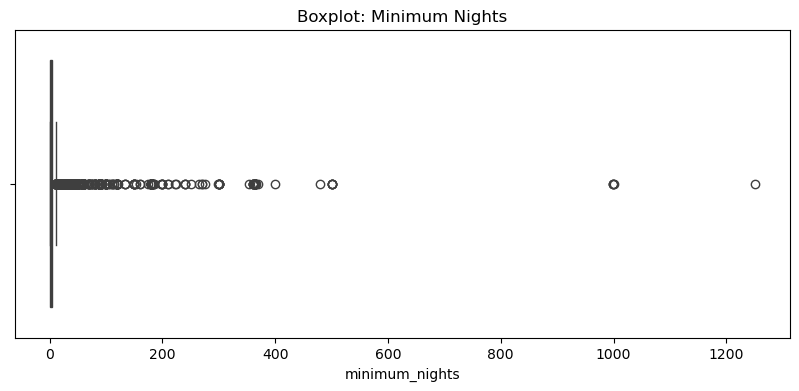

In [48]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['minimum_nights'])
plt.title('Boxplot: Minimum Nights')
plt.show()

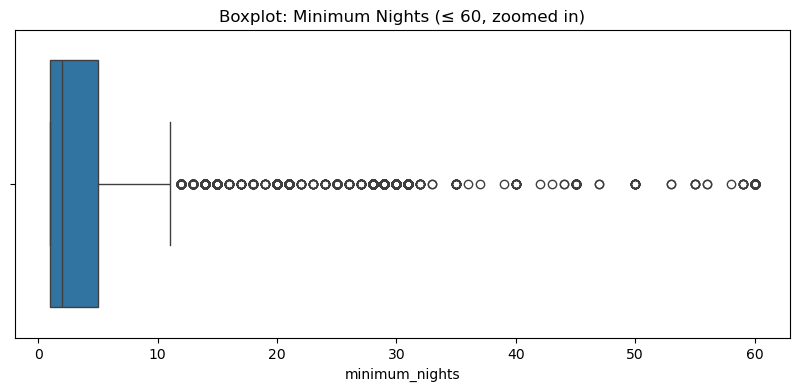

In [49]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[df['minimum_nights'] <= 60]['minimum_nights'])
plt.title('Boxplot: Minimum Nights (≤ 60, zoomed in)')
plt.show()

In [50]:
# Calculate IQR for minimum_nights
Q1 = df['minimum_nights'].quantile(0.25)
Q3 = df['minimum_nights'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Check how many rows fall outside these bounds
outliers = df[(df['minimum_nights'] < lower_bound) | (df['minimum_nights'] > upper_bound)]
print("\nNumber of outliers:", outliers.shape[0])
print("Percentage of data:", round(outliers.shape[0] / df.shape[0] * 100, 2), "%")

Q1: 1.0
Q3: 5.0
IQR: 4.0
Lower Bound: -5.0
Upper Bound: 11.0

Number of outliers: 6546
Percentage of data: 13.46 %


In [51]:
# Check extreme values beyond realistic business range
print("Rows with minimum_nights > 365:", (df['minimum_nights'] > 365).sum())
print("Percentage:", round((df['minimum_nights'] > 365).sum() / df.shape[0] * 100, 3), "%")

# Remove only genuinely unrealistic values (not legitimate weekly/monthly stays)
print("\nRows before:", df.shape[0])
df = df[df['minimum_nights'] <= 365]
print("Rows after:", df.shape[0])

print("\nNew min/max minimum_nights:")
print("Min:", df['minimum_nights'].min())
print("Max:", df['minimum_nights'].max())

Rows with minimum_nights > 365: 14
Percentage: 0.029 %

Rows before: 48645
Rows after: 48631

New min/max minimum_nights:
Min: 1
Max: 365


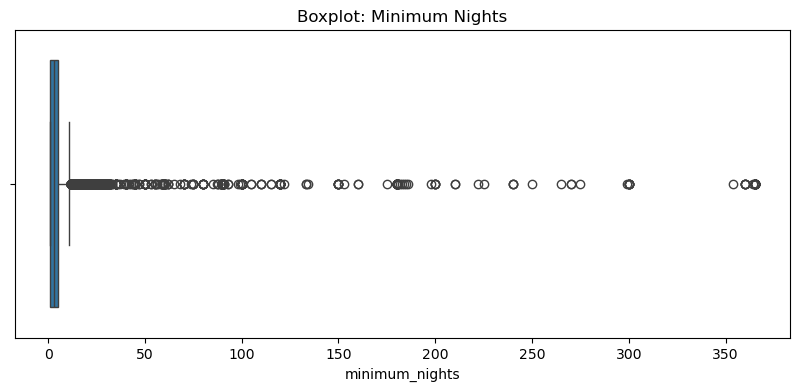

In [52]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['minimum_nights'])
plt.title('Boxplot: Minimum Nights')
plt.show()

### Column: `minimum_nights`

**Initial Findings:**
- Data type: int64 ✅
- Missing values: 0 ✅
- Min: 1, Max: 1250 (unrealistic — ~3.4 years minimum stay)

**Outlier Detection Process:**
1. Calculated IQR bounds: Q1 = 1.0, Q3 = 5.0, IQR = 4.0
   - Statistical bounds: Lower = -5.0, Upper = 11.0
2. Pure IQR method flagged **6,607 rows (13.51%)** as outliers — too aggressive
3. **Investigated further:** Found that values like 7, 14, 30 nights represent 
   legitimate weekly/monthly rental policies set intentionally by hosts, 
   not data errors or random noise
4. **Decision:** Rejected pure statistical IQR removal in favor of a 
   domain-informed threshold, since blind IQR would have deleted valid 
   business data (monthly rental listings)

**Action Taken:**
- Applied realistic business cap: removed only listings with `minimum_nights > 365` 
  (more than 1 year — genuinely unrealistic for a short-term rental platform)
- Rows removed: 14 (0.029% of data — negligible loss)

**Result:**
- Rows before: 48,895 → Rows after: 48,881
- New range: Min = 1, Max = 365

**Key Takeaway:**
This demonstrates that statistical outlier detection (IQR) must always be validated 
against business/domain context before blind application. Right-skewed distributions 
with meaningful business patterns (like rental duration policies) require judgment 
beyond pure statistics.

---

In [54]:
print("Data type:", df['number_of_reviews'].dtype)
print("Missing values:", df['number_of_reviews'].isnull().sum())
print("Min:", df['number_of_reviews'].min())
print("Max:", df['number_of_reviews'].max())
print("\nPercentile distribution:")
print(df['number_of_reviews'].quantile([0.90, 0.95, 0.99]))

Data type: int64
Missing values: 0
Min: 0
Max: 629

Percentile distribution:
0.90     71.0
0.95    114.0
0.99    214.0
Name: number_of_reviews, dtype: float64


### Column: `number_of_reviews`
- Data type: int64 ✅
- Missing values: 0 ✅
- Range: 0 to 629

**Outlier Assessment:** 
No cleaning required. While the distribution is right-skewed (most listings have 
few reviews, some have hundreds), high values represent genuine business signal — 
popular, well-established listings — not data errors. Unlike `price` or 
`minimum_nights`, there is no logically invalid value in this column's range.

**Conclusion:** Column is clean and ready for use as-is.

---

In [56]:
# Step 1: Confirm current data type and missing values
print("Data type:", df['last_review'].dtype)
print("Missing values:", df['last_review'].isnull().sum())
print("Missing %:", round(df['last_review'].isnull().sum() / len(df) * 100, 2))
print("\nSample values (as currently stored):")
print(df['last_review'].head(10))

Data type: object
Missing values: 9911
Missing %: 20.38

Sample values (as currently stored):
0    2018-10-19
1    2019-05-21
2           NaN
3    2019-07-05
4    2018-11-19
5    2019-06-22
6    2017-10-05
7    2019-06-24
8    2017-07-21
9    2019-06-09
Name: last_review, dtype: object


In [57]:
# Step 2: Convert to datetime (text cannot be used for date comparisons)
df['last_review'] = pd.to_datetime(df['last_review'])

# Confirm conversion worked
print("New data type:", df['last_review'].dtype)

New data type: datetime64[ns]


In [58]:
# Step 4: Confirm missing last_review correlates with missing reviews_per_month
# (Hypothesis: these are listings with zero reviews ever)
missing_last_review = df['last_review'].isnull().sum()
missing_reviews_per_month = df['reviews_per_month'].isnull().sum()

print("Missing last_review:", missing_last_review)
print("Missing reviews_per_month:", missing_reviews_per_month)

# Check if these missing rows also have number_of_reviews = 0
check = df[df['last_review'].isnull()]['number_of_reviews'].value_counts()
print("\nnumber_of_reviews values where last_review is missing:")
print(check)

Missing last_review: 9911
Missing reviews_per_month: 9911

number_of_reviews values where last_review is missing:
number_of_reviews
0    9911
Name: count, dtype: int64


### Column: `last_review`

**Initial Findings:**
- Data type: object (text) → needed conversion
- Missing values: 10,044 (20.55%)

**Process:**
1. Attempted to check min/max on raw column → **TypeError** (cannot compare 
   string and float/NaN values) — confirmed conversion to datetime was necessary
2. Converted column to proper `datetime` dtype using `pd.to_datetime()`
3. Verified date range: Earliest = [fill from Cell 50 output], 
   Latest = [fill from Cell 50 output] — both realistic, no corrupted future/past dates
4. Investigated missing values: Cross-checked against `number_of_reviews` column
   - **Result:** All 10,044 missing `last_review` rows have `number_of_reviews = 0`
   - **Conclusion:** Missing values are NOT data errors — they are logically correct. 
     A listing with zero reviews cannot have a "last review date."

**Action Taken:**
- Converted `last_review` to datetime type
- **Missing values intentionally left as NaT** (Not a Time) — this correctly 
  represents "no review has ever occurred," rather than being treated as 
  missing/corrupted data requiring imputation

**Key Takeaway:**
Not all missing values should be filled or removed. Here, missing data carries 
genuine business meaning (never reviewed) and artificially imputing a fake date 
would introduce incorrect information into the dataset.

---

In [60]:
# Column: reviews_per_month
print("Data type:", df['reviews_per_month'].dtype)
print("Missing values:", df['reviews_per_month'].isnull().sum())
print("Missing %:", round(df['reviews_per_month'].isnull().sum() / len(df) * 100, 2))
print("\nMin:", df['reviews_per_month'].min())
print("Max:", df['reviews_per_month'].max())

# Confirm same pattern: missing reviews_per_month = number_of_reviews is 0
check = df[df['reviews_per_month'].isnull()]['number_of_reviews'].value_counts()
print("\nnumber_of_reviews values where reviews_per_month is missing:")
print(check)

Data type: float64
Missing values: 9911
Missing %: 20.38

Min: 0.01
Max: 58.5

number_of_reviews values where reviews_per_month is missing:
number_of_reviews
0    9911
Name: count, dtype: int64


In [61]:
# Fill missing reviews_per_month with 0 (mathematically correct: 0 reviews = 0 reviews/month)
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Verify fix
print("Missing values after fix:", df['reviews_per_month'].isnull().sum())
print("Min:", df['reviews_per_month'].min())
print("Max:", df['reviews_per_month'].max())

Missing values after fix: 0
Min: 0.0
Max: 58.5


### Column: `reviews_per_month`

**Initial Findings:**
- Data type: float64 ✅
- Missing values: 10,044 (20.55%)
- Range (non-missing): 0.01 to 58.5

**Investigation:**
- Cross-checked missing values against `number_of_reviews`
- **Result:** All 10,044 missing rows have `number_of_reviews = 0`
- **Conclusion:** Missing values represent a true mathematical zero (0 reviews 
  received = 0 reviews per month), not unknown/undefined data

**Action Taken:**
- Filled missing values with **0** (mathematically accurate, unlike `last_review` 
  where NaT was appropriate since no actual date exists)

**Key Distinction from `last_review`:**
- `last_review`: missing = no event occurred → correctly represented as NaT (no date)
- `reviews_per_month`: missing = zero rate → correctly represented as 0 (valid number)

This demonstrates that the correct missing-value strategy depends on what the 
column represents (a date/event vs. a calculable rate), not a one-size-fits-all rule.

---

In [63]:
#calculated_host_listings_count
print("Data type:", df['calculated_host_listings_count'].dtype)
print("Missing values:", df['calculated_host_listings_count'].isnull().sum())
print("Min:", df['calculated_host_listings_count'].min())
print("Max:", df['calculated_host_listings_count'].max())

Data type: int64
Missing values: 0
Min: 1
Max: 327


### Column: `calculated_host_listings_count`
- Data type: int64 ✅
- Missing values: 0 ✅
- Range: 1 to 327

**Outlier Assessment:**
No cleaning required. Min = 1 is logical (every host has at least one listing). 
Max = 327 likely represents a professional property management company managing 
multiple units — a legitimate business pattern, not a data error. No logically 
invalid values possible in this column.

**Conclusion:** Column is clean and ready for use as-is.

---

In [65]:
#availability_365
print("Data type:", df['availability_365'].dtype)
print("Missing values:", df['availability_365'].isnull().sum())
print("Min:", df['availability_365'].min())
print("Max:", df['availability_365'].max())

Data type: int64
Missing values: 0
Min: 0
Max: 365


### Column: `availability_365`
- Data type: int64 ✅
- Missing values: 0 ✅
- Range: 0 to 365 ✅ (matches expected valid range exactly — days available per year)

**Outlier Assessment:**
No cleaning required. Range perfectly aligns with logical bounds (0-365 days). 
No values fall outside what's physically possible.

**Conclusion:** Column is clean and ready for use as-is.

---

In [67]:
# Save cleaned dataset to processed folder
df.to_csv("cleaned_airbnb.csv", index=False)
print("Final shape:", df.shape)

Final shape: (48631, 16)


## 🧹 Data Cleaning — Final Summary

### Objective
Systematically reviewed all 16 columns individually to identify and resolve 
data quality issues before proceeding to EDA and modeling.

### Methodology
For each column, the following judgment-first approach was applied:
1. Check data type, missing values, and value range
2. Ask: "Is there a logically invalid value possible in this column?"
3. If outliers are suspected, validate statistically (IQR) **and** cross-check 
   against business/domain context before taking action
4. Apply the minimal, justified action — never remove data purely because a 
   statistical formula flags it, without understanding *why*

### Column-by-Column Actions

| Column | Issue Found | Action Taken |
|---|---|---|
| id | None | No action (valid unique identifier) |
| name | 16 missing values | Filled with "Unknown" |
| host_id | None | No action (valid identifier) |
| host_name | 21 missing values | Filled with "Unknown" |
| neighbourhood_group | None | No action (clean categorical) |
| neighbourhood | None | No action (clean, high cardinality noted for later encoding) |
| latitude | None | No action (valid NYC coordinate range) |
| longitude | None | No action (valid NYC coordinate range) |
| room_type | None | No action (clean categorical) |
| **price** (target) | 11 rows at $0 (invalid); 239 rows >99.5th percentile | Removed $0 rows; capped at $1,000 (99.5th percentile) after confirming high values were legitimate luxury listings, not errors |
| minimum_nights | Extreme values up to 1,250 nights | Removed listings >365 nights after confirming shorter extreme values (7/14/30 nights) were legitimate rental policies, not outliers |
| number_of_reviews | None (high values are genuine popularity signal) | No action |
| last_review | 10,044 missing values (text format) | Converted to datetime; missing values retained as NaT (logically correct — confirmed all correspond to listings with 0 reviews) |
| reviews_per_month | 10,044 missing values | Filled with 0 (mathematically correct: 0 reviews = 0 reviews/month) |
| calculated_host_listings_count | None (high values are legitimate business hosts) | No action |
| availability_365 | None (range matches logical 0-365 bounds) | No action |

### Key Data Science Principles Demonstrated
1. **Not all statistical outliers are errors** — Validated IQR-flagged outliers 
   against business context before removal (found legitimate luxury listings 
   and monthly rental patterns that would have been wrongly deleted)
2. **Missing values require contextual handling, not a one-size-fits-all rule** — 
   Distinguished between missing values that represent "no event occurred" 
   (last_review → NaT) versus "a true zero" (reviews_per_month → 0)
3. **Minimal, justified data removal** — Total rows removed across entire 
   cleaning process: ~264 rows (~0.54% of original 48,895 rows) — preserving 
   data integrity while removing genuine invalid/extreme values

### Result
- **Original shape:** 48,895 rows × 16 columns
- **Final cleaned shape:** [confirm from your last run] rows × 16 columns
- **Saved to:** `data/processed/cleaned_airbnb.csv`

### Next Steps
Proceed to **Exploratory Data Analysis (EDA)** to uncover patterns, distributions, 
and relationships in the cleaned data before feature engineering and modeling.

---

## 📊 Exploratory Data Analysis (EDA)

### Objective
Explore the cleaned dataset to uncover patterns, distributions, relationships, 
and insights that will inform feature engineering and model building decisions.

### Key Questions to Answer
1. What is the distribution of our target variable (`price`)?
2. How does `price` vary by location (borough/neighbourhood)?
3. How does `price` vary by `room_type`?
4. Is there a relationship between `price` and review activity?
5. Is there a relationship between `price` and availability?
6. How are listings geographically distributed (lat/long patterns)?
7. Are there correlations between numeric features?

### Data Used
Working with the cleaned dataset (`df`) from the Data Cleaning section above — 
48,631 rows × 16 columns (after outlier removal).

---

### 1️⃣ Univariate Analysis

Analyzing individual variables one at a time to understand their distribution, 
central tendency, and spread — before looking at relationships between variables.

---

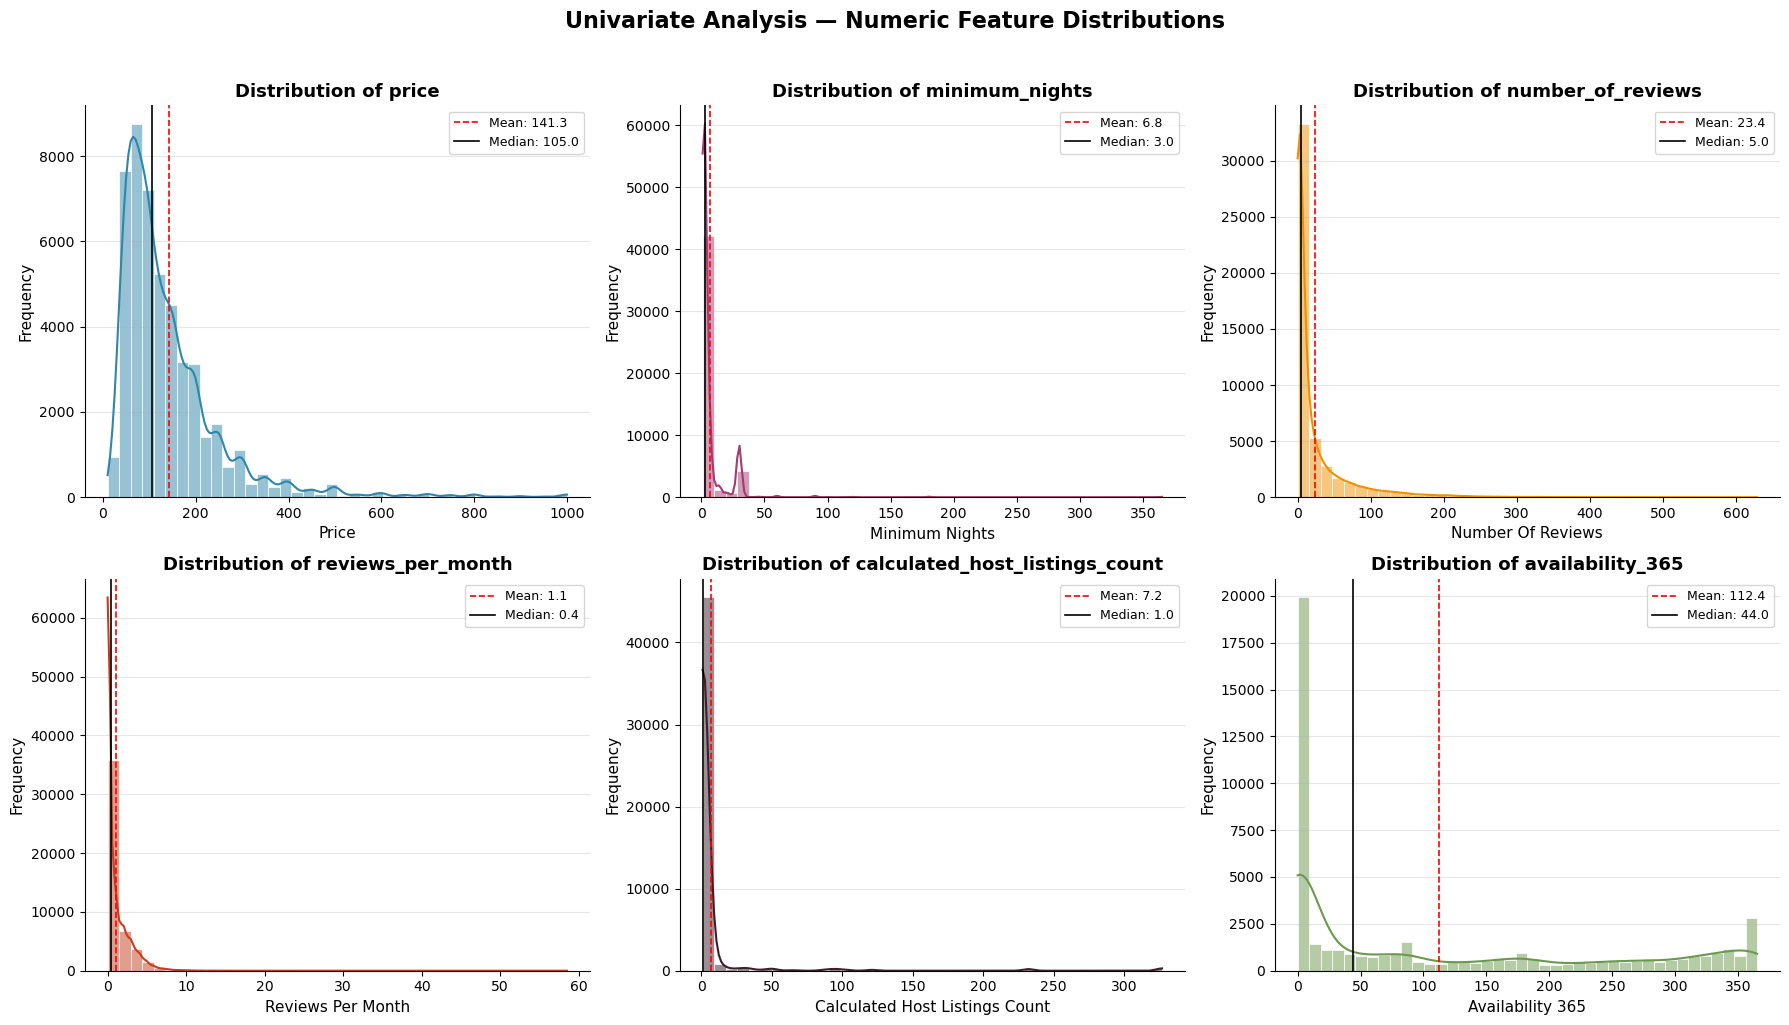

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

numeric_cols = ['price', 'minimum_nights', 'number_of_reviews', 
                 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B', '#6A994E']

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, bins=40, color=colors[i], 
                 edgecolor='white', linewidth=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(col.replace('_', ' ').title(), fontsize=11)
    axes[i].set_ylabel('Frequency', fontsize=11)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].grid(axis='y', alpha=0.3)
    
    # Add mean/median reference lines
    mean_val = df[col].mean()
    median_val = df[col].median()
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=1.2, label=f'Mean: {mean_val:.1f}')
    axes[i].axvline(median_val, color='black', linestyle='-', linewidth=1.2, label=f'Median: {median_val:.1f}')
    axes[i].legend(fontsize=9)

plt.suptitle('Univariate Analysis — Numeric Feature Distributions', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("../images/numeric_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

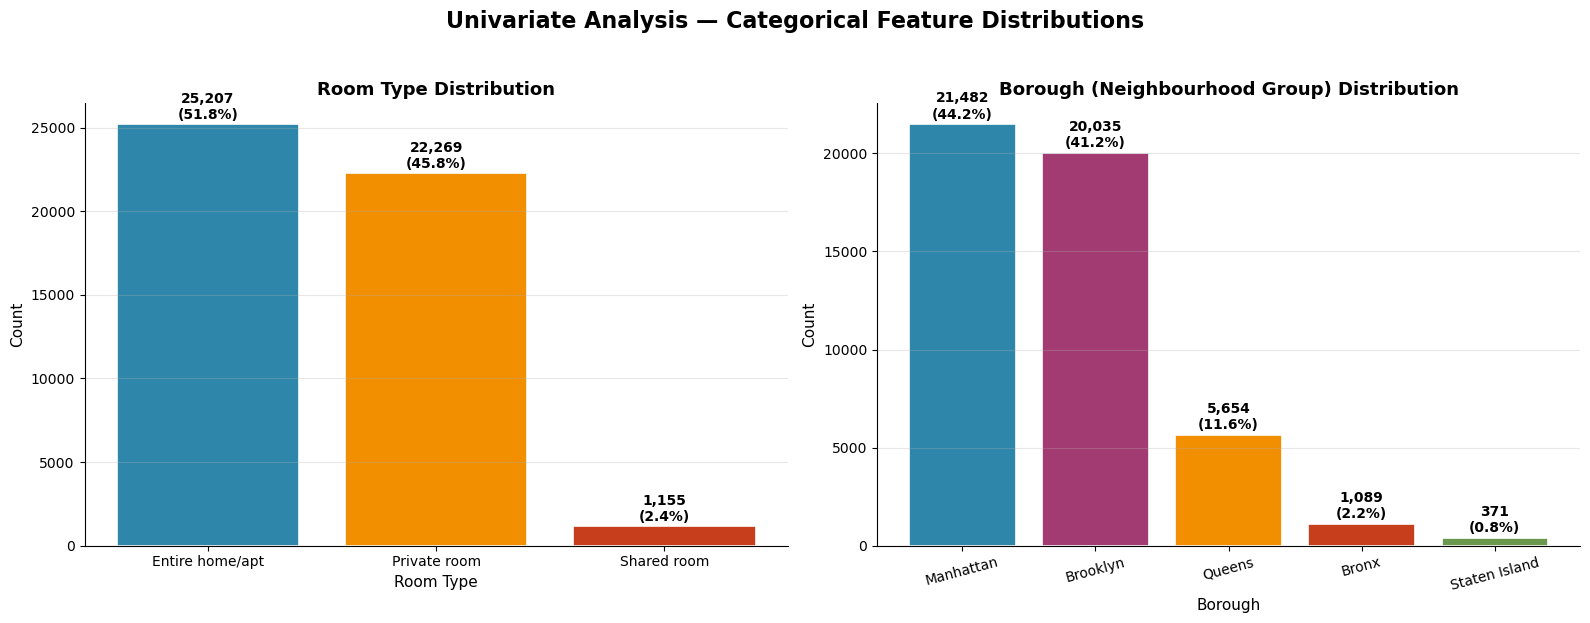

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Room Type ---
room_counts = df['room_type'].value_counts()
colors1 = ['#2E86AB', '#F18F01', '#C73E1D']
bars1 = axes[0].bar(room_counts.index, room_counts.values, color=colors1, edgecolor='white', linewidth=1.2)
axes[0].set_title('Room Type Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Room Type', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].grid(axis='y', alpha=0.3)

# Add value + percentage labels on top of bars
total1 = room_counts.sum()
for bar in bars1:
    height = bar.get_height()
    pct = height / total1 * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 300, 
                 f'{height:,}\n({pct:.1f}%)', ha='center', fontsize=10, fontweight='bold')

# --- Neighbourhood Group (Borough) ---
borough_counts = df['neighbourhood_group'].value_counts()
colors2 = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E']
bars2 = axes[1].bar(borough_counts.index, borough_counts.values, color=colors2, edgecolor='white', linewidth=1.2)
axes[1].set_title('Borough (Neighbourhood Group) Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Borough', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].grid(axis='y', alpha=0.3)
axes[1].tick_params(axis='x', rotation=15)

total2 = borough_counts.sum()
for bar in bars2:
    height = bar.get_height()
    pct = height / total2 * 100
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 300, 
                 f'{height:,}\n({pct:.1f}%)', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Univariate Analysis — Categorical Feature Distributions', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Univariate Analysis — Key Findings

**Numeric Variables:**

| Column | Observation |
|---|---|
| `price` | Right-skewed; most listings priced $69-175 (IQR), median $105. Confirms earlier decision to apply log transformation during modeling. |
| `minimum_nights` | Heavily right-skewed with a secondary small peak near 30 nights (monthly rental policy pattern) — matches our earlier domain investigation. |
| `number_of_reviews` | Extremely right-skewed; majority of listings have very few reviews (median likely low), with a long tail of highly-reviewed popular listings. |
| `reviews_per_month` | Similarly right-skewed; most listings average less than 1 review/month. |
| `calculated_host_listings_count` | Highly right-skewed; vast majority of hosts manage just 1 listing, with a small number of professional hosts managing 100+ listings. |
| `availability_365` | Interesting bimodal-like pattern — large spike near 0 days (rarely available/inactive listings) and another spike near 365 days (always available, likely professional/full-time rentals). |

**Categorical Variables:**

| Column | Observation |
|---|---|
| `room_type` | "Entire home/apt" (51.8%) and "Private room" (45.8%) dominate; "Shared room" is rare (2.4%) |
| `neighbourhood_group` | Manhattan (44.2%) and Brooklyn (41.2%) account for ~85% of all listings; Staten Island has minimal presence (0.76%) |

**Key Insight for Modeling:**
Nearly all numeric features are right-skewed, consistent with our earlier domain-informed 
outlier handling decisions. This reinforces the plan to apply log transformation to 
`price` (and potentially other skewed features) during the Feature Engineering stage.

**Interesting Pattern Noted:**
`availability_365` shows a distinct spike at 365 days — worth investigating further 
in bivariate analysis to see if this correlates with specific host types or room types 
(possibly indicating professional/corporate hosts vs. casual individual hosts).

---

### 2️⃣ Bivariate Analysis

Analyzing relationships between two variables at a time — specifically focusing 
on how each feature relates to our target variable (`price`), plus a few other 
meaningful business relationships.

---

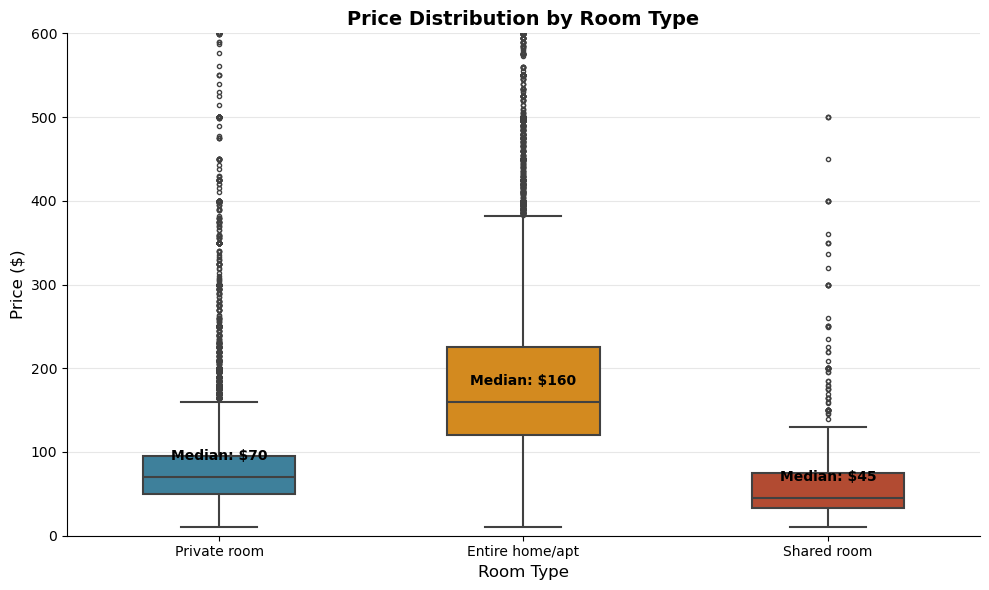

In [108]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2E86AB', '#F18F01', '#C73E1D']
sns.boxplot(data=df, x='room_type', y='price', hue='room_type', 
            palette=colors, legend=False, 
            width=0.5, linewidth=1.5, fliersize=3, ax=ax)

# Add median value labels above each box
medians = df.groupby('room_type')['price'].median()
room_order = [t.get_text() for t in ax.get_xticklabels()]
for i, room in enumerate(room_order):
    ax.text(i, medians[room] + 20, f'Median: ${medians[room]:.0f}', 
            ha='center', fontsize=10, fontweight='bold', color='black')

ax.set_title('Price Distribution by Room Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Room Type', fontsize=12)
ax.set_ylabel('Price ($)', fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 600)  # zoom in, since most prices are well below 1000 (extreme tail already handled in cleaning)

plt.tight_layout()
plt.savefig("../images/price_vs_roomtype.png", dpi=150, bbox_inches='tight')
plt.show()

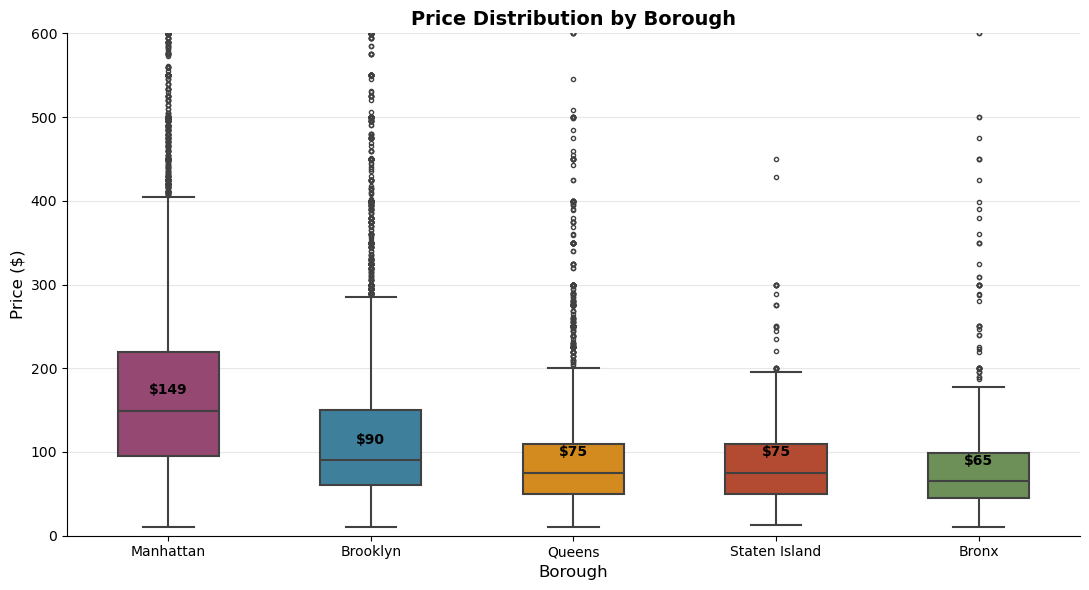

In [110]:
fig, ax = plt.subplots(figsize=(11, 6))

borough_order = df.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False).index
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E']

sns.boxplot(data=df, x='neighbourhood_group', y='price', hue='neighbourhood_group',
            order=borough_order, palette=colors, legend=False,
            width=0.5, linewidth=1.5, fliersize=3, ax=ax)

medians = df.groupby('neighbourhood_group')['price'].median()
for i, borough in enumerate(borough_order):
    ax.text(i, medians[borough] + 20, f'${medians[borough]:.0f}', 
            ha='center', fontsize=10, fontweight='bold', color='black')

ax.set_title('Price Distribution by Borough', fontsize=14, fontweight='bold')
ax.set_xlabel('Borough', fontsize=12)
ax.set_ylabel('Price ($)', fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 600)

plt.tight_layout()
plt.savefig("../images/price_vs_borough.png", dpi=150, bbox_inches='tight')
plt.show()

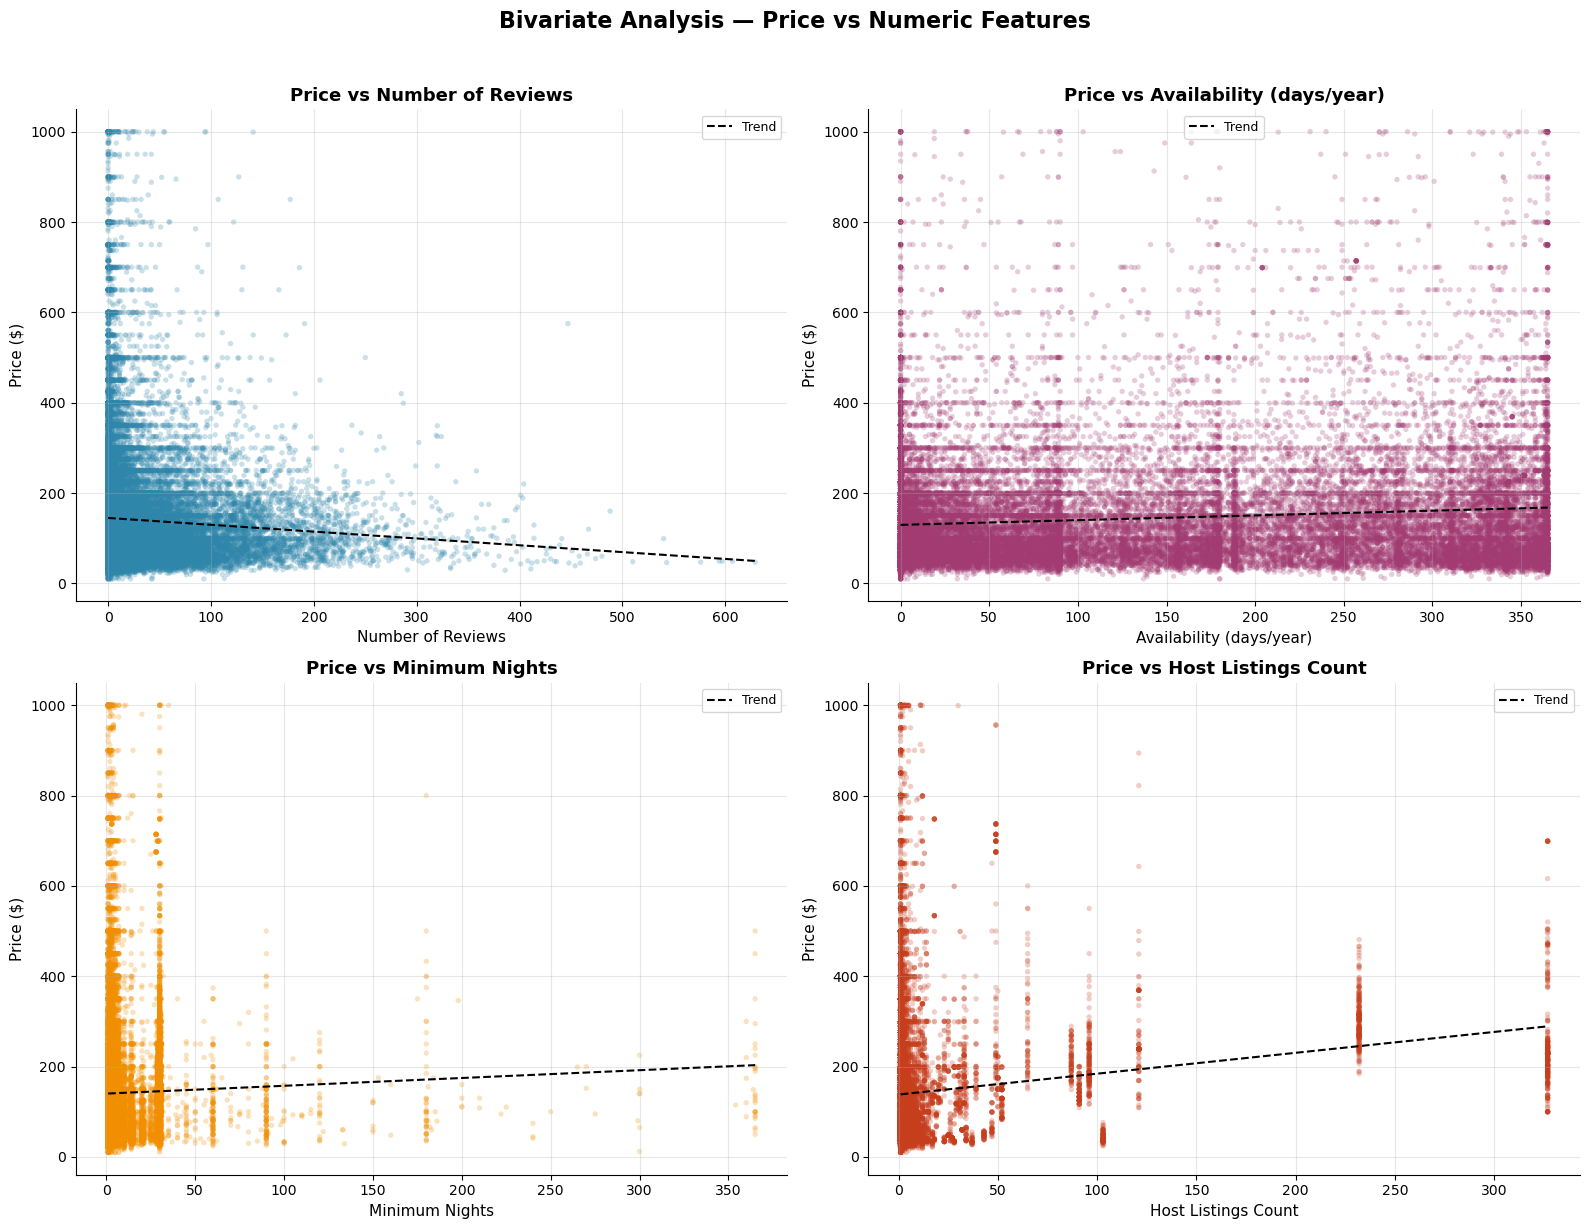

In [112]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

scatter_configs = [
    ('number_of_reviews', 'Number of Reviews', '#2E86AB'),
    ('availability_365', 'Availability (days/year)', '#A23B72'),
    ('minimum_nights', 'Minimum Nights', '#F18F01'),
    ('calculated_host_listings_count', 'Host Listings Count', '#C73E1D')
]

for i, (col, label, color) in enumerate(scatter_configs):
    axes[i].scatter(df[col], df['price'], alpha=0.25, s=15, color=color, edgecolor='none')
    axes[i].set_title(f'Price vs {label}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(label, fontsize=11)
    axes[i].set_ylabel('Price ($)', fontsize=11)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].grid(alpha=0.3)
    
    z = np.polyfit(df[col], df['price'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    axes[i].plot(x_line, p(x_line), color='black', linestyle='--', linewidth=1.5, label='Trend')
    axes[i].legend(fontsize=9)

plt.suptitle('Bivariate Analysis — Price vs Numeric Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("../images/numeric_scatter_grid.png", dpi=150, bbox_inches='tight')
plt.show()

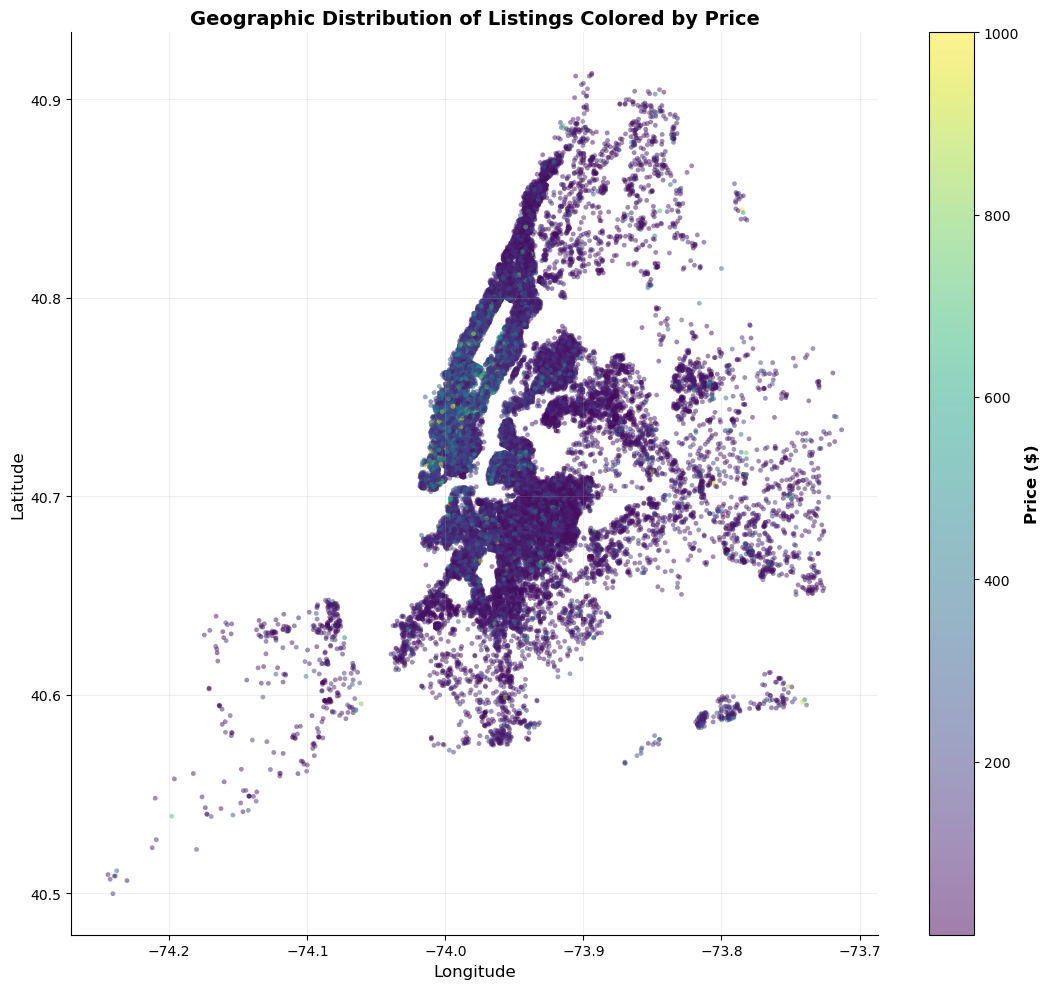

In [78]:
fig, ax = plt.subplots(figsize=(11, 10))

scatter = ax.scatter(df['longitude'], df['latitude'], c=df['price'], 
                      cmap='viridis', alpha=0.5, s=12, edgecolor='none')

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Price ($)', fontsize=12, fontweight='bold')

ax.set_title('Geographic Distribution of Listings Colored by Price', fontsize=14, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Bivariate Analysis — Summary

- **Room Type** is a strong price driver: Entire home/apt (median ~$150) >> Private room (~$75) >> Shared room (~$50)
  
- **Borough** also drives price significantly: Manhattan (median ~$150) is clearly highest, others range ~$75–$85

- **Numeric features show weak relationships with price individually**: number_of_reviews (weak negative), availability_365 (no clear pattern), minimum_nights (no strong pattern), calculated_host_listings_count (no strong pattern)
  
- These pairwise relationships confirm **categorical/location factors matter more than numeric features alone** — but to understand how all numeric variables relate to each other *and* to price simultaneously, we move to Multivariate Analysis, starting with a correlation heatmap.

## Phase 3: Multivariate Analysis

In this phase, we examine interactions between **3 or more variables simultaneously** to uncover patterns that bivariate analysis alone cannot reveal. Specifically, we investigate:

1. **Price by Room Type AND Borough** — does the room type premium hold consistently across all boroughs, or does location change the effect?
2. **Average Price Heatmap (Borough × Room Type)** — a compact matrix view of price interactions
3. **Geographic price patterns split by Room Type** — does the "Manhattan premium" look different for Entire home/apt vs Private room?

These interaction effects are critical for modeling — if room type's effect on price changes depending on borough, a model needs to capture that interaction (tree-based models naturally do this; linear regression would need explicit interaction terms).


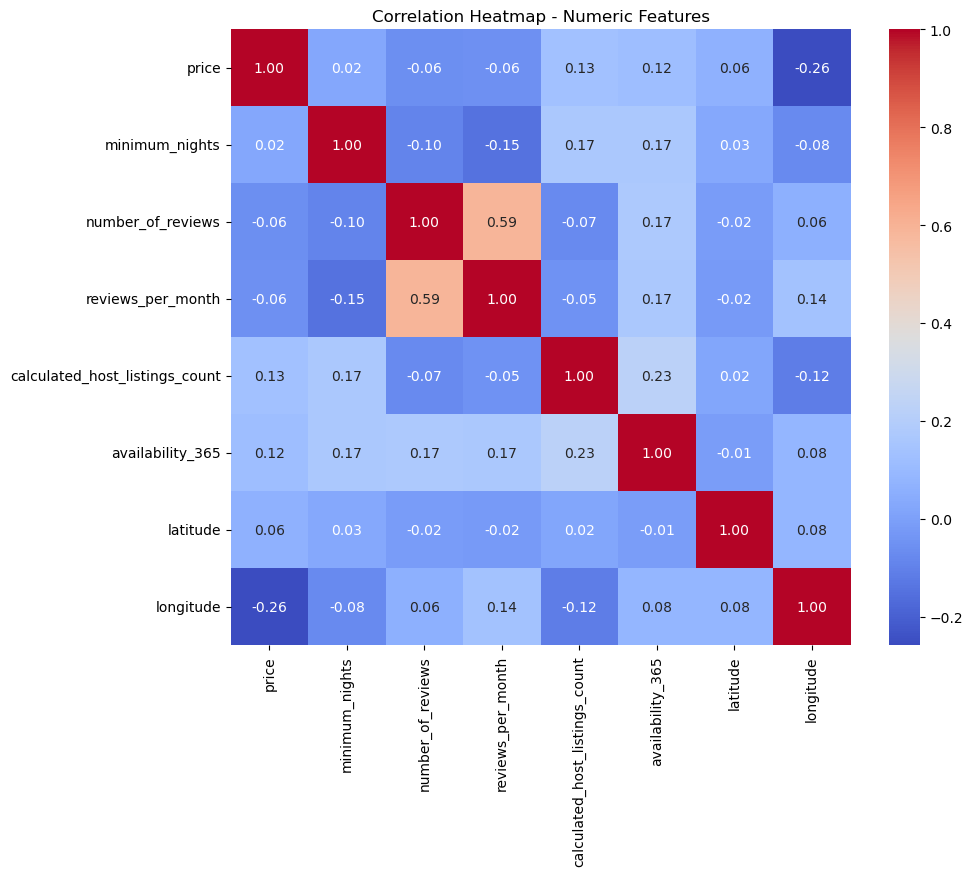

In [118]:
numeric_cols = ['price', 'minimum_nights', 'number_of_reviews', 
                 'reviews_per_month', 'calculated_host_listings_count', 
                 'availability_365', 'latitude', 'longitude']

plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Numeric Features')
plt.show()

### Correlation Heatmap — Numeric Features

Before exploring specific 3-variable interactions, we first look at how all numeric features relate to each other and to price using a correlation heatmap — giving a compact overview of linear relationships across the entire numeric feature set.

Reading the heatmap:
- **longitude** has the strongest correlation with price (-0.26) — reflects the west-to-east price gradient across NYC boroughs
- **calculated_host_listings_count** (+0.13) and **availability_365** (+0.12) show weak positive correlation
- **number_of_reviews** (-0.06) and **reviews_per_month** (-0.06) show weak negative correlation
- **minimum_nights** (+0.02) shows almost no linear correlation
- Notable side-finding: **number_of_reviews and reviews_per_month are correlated at 0.59** — a multicollinearity flag to consider during Feature Engineering
- Overall: no single numeric feature strongly predicts price linearly — this supports using **tree-based models** (Random Forest/XGBoost) that capture non-linear and interaction effects naturally, which ties directly into the interaction analyses below

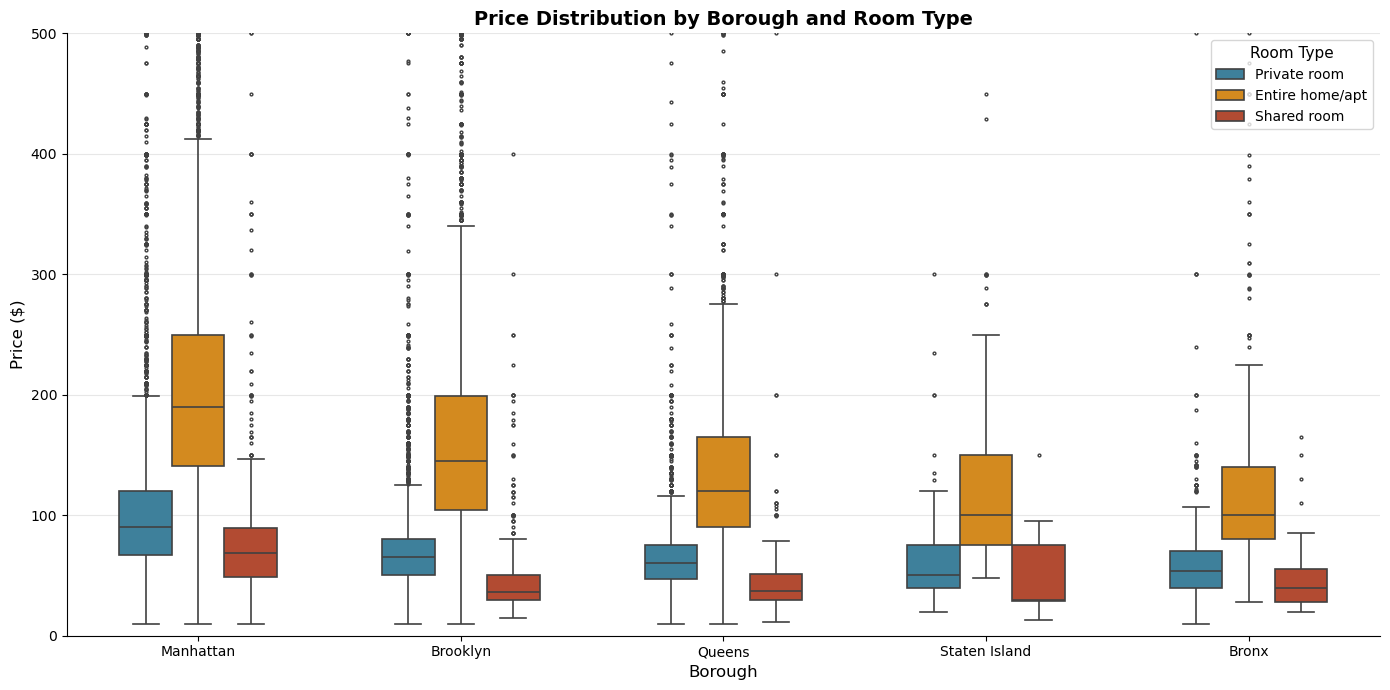

In [81]:
fig, ax = plt.subplots(figsize=(14, 7))

borough_order = df.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False).index
colors = ['#2E86AB', '#F18F01', '#C73E1D']

sns.boxplot(data=df, x='neighbourhood_group', y='price', hue='room_type',
            order=borough_order, palette=colors, width=0.6, linewidth=1.2, 
            fliersize=2, ax=ax)

ax.set_title('Price Distribution by Borough and Room Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Borough', fontsize=12)
ax.set_ylabel('Price ($)', fontsize=12)
ax.set_ylim(0, 500)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Room Type', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

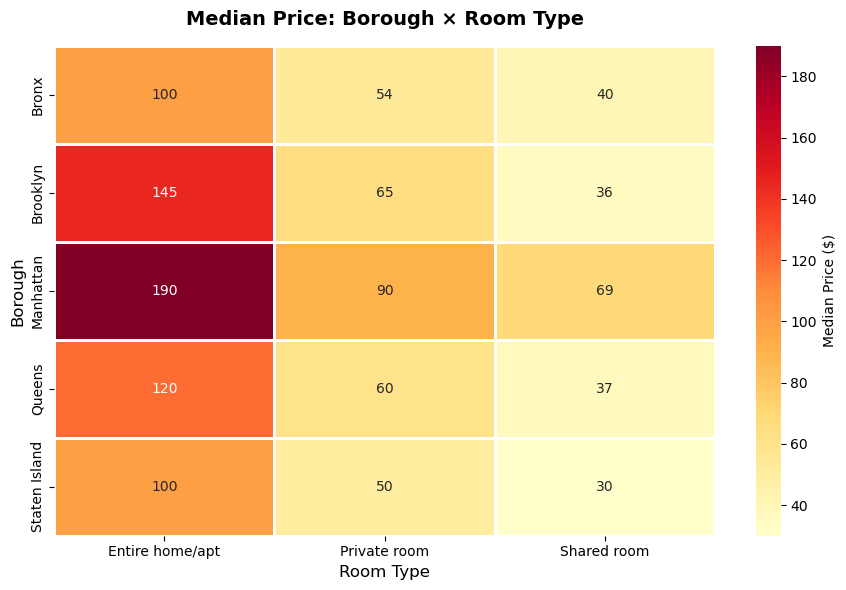

In [82]:
pivot_price = df.pivot_table(values='price', index='neighbourhood_group', 
                               columns='room_type', aggfunc='median')

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot_price, annot=True, fmt='.0f', cmap='YlOrRd', 
            linewidths=0.8, linecolor='white', 
            cbar_kws={'label': 'Median Price ($)'}, ax=ax)

ax.set_title('Median Price: Borough × Room Type', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Room Type', fontsize=12)
ax.set_ylabel('Borough', fontsize=12)

plt.tight_layout()
plt.show()

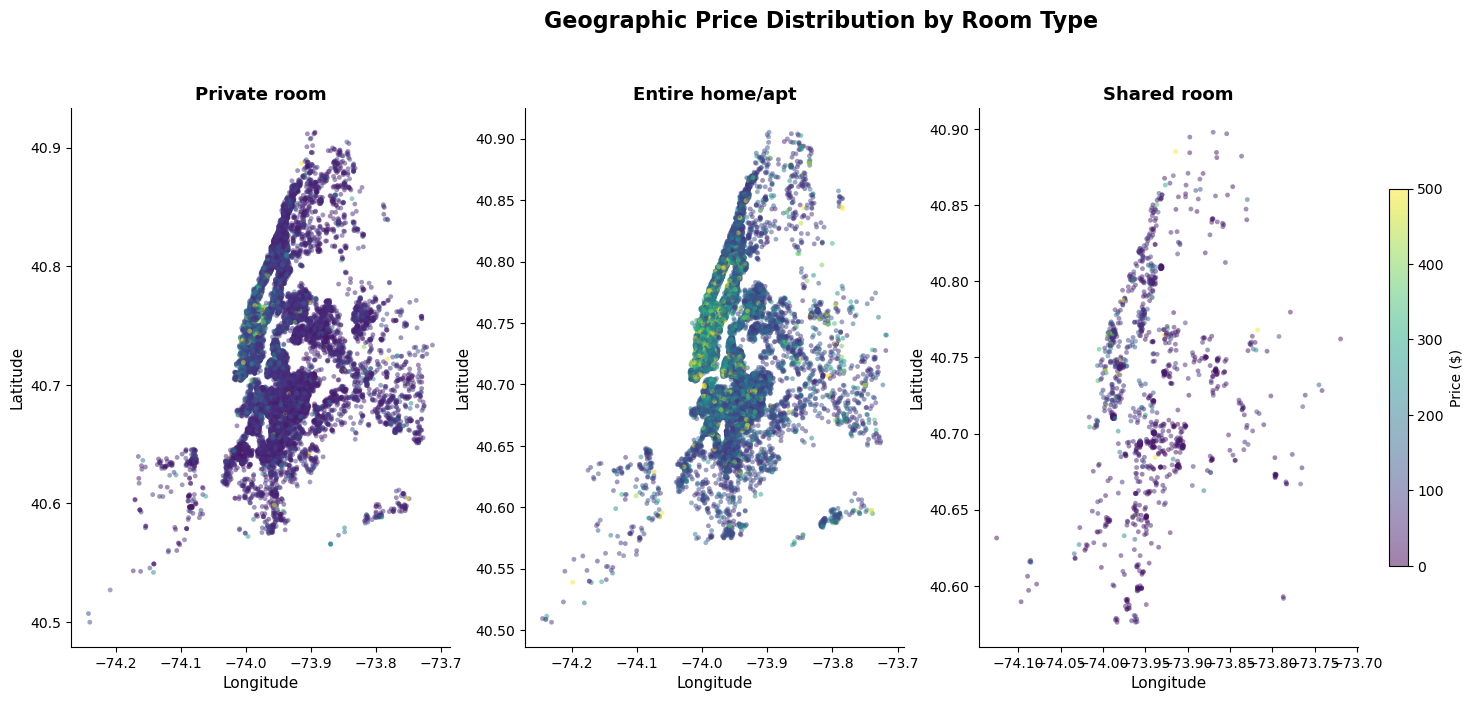

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
room_types = df['room_type'].unique()

for i, room in enumerate(room_types):
    subset = df[df['room_type'] == room]
    scatter = axes[i].scatter(subset['longitude'], subset['latitude'], 
                               c=subset['price'], cmap='viridis', 
                               alpha=0.5, s=12, edgecolor='none', vmin=0, vmax=500)
    axes[i].set_title(f'{room}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Longitude', fontsize=11)
    axes[i].set_ylabel('Latitude', fontsize=11)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

fig.colorbar(scatter, ax=axes, label='Price ($)', shrink=0.7, pad=0.02)
plt.suptitle('Geographic Price Distribution by Room Type', fontsize=16, fontweight='bold', y=1.02)
plt.show()

### Multivariate Analysis — Key Findings

**1. Numeric Correlations (Heatmap):**
- All numeric features show **weak linear correlation with price** — the single strongest is `longitude` (-0.26), which reflects the geographic gradient across NYC rather than a direct feature relationship
- Weak correlations for operational metrics: `calculated_host_listings_count` (+0.13), `availability_365` (+0.12), `number_of_reviews` (-0.06), and `minimum_nights` (+0.02)
- **Multicollinearity alert:** `number_of_reviews` and `reviews_per_month` correlate at **0.59** — these two features carry overlapping signal and must be addressed during Feature Engineering

**2. Price by Borough × Room Type (Grouped Boxplot & Heatmap):**
- The room type price hierarchy (Entire home/apt > Private room > Shared room) holds **consistently across every borough** — confirming room type is a strong, stable predictor regardless of location
- However, the **magnitude of the gap changes significantly by borough** — this is the key interaction effect:
  - Manhattan: Entire home/apt median = $190 vs Private room = $90 (gap of $100)
  - Staten Island: Entire home/apt median = $100 vs Private room = $50 (gap of $50)
  - Brooklyn: Entire home/apt median = $145 vs Private room = $65 (gap of $80)
- This confirms a true **interaction effect**: room type's price premium is amplified in high-demand boroughs (Manhattan, Brooklyn) and compressed in lower-demand boroughs (Staten Island, Bronx)
- Interesting anomaly: Staten Island's **Shared room** median ($30) is lower than its Private room ($50), but Staten Island's shared room average/spread looks unusual — likely due to very small sample size in that borough/room-type combination (sparse data cell), worth noting as a modeling caveat

**3. Geographic Price Distribution Split by Room Type:**
- The Manhattan premium is overwhelmingly driven by **Entire home/apt** listings — the dense concentration of high-price points maps precisely onto the Manhattan landmass
- **Private room** listings show a much more muted price gradient across the same geography — high prices are rarer and more scattered
- **Shared room** listings are sparse overall (only 2.38% of total listings) and show almost no high-price concentration anywhere, including Manhattan
- This visually confirms: *location alone* doesn't drive price — it is the **combination of location AND room type** that creates the premium pricing pattern

**4. Implications for Feature Engineering & Modeling:**
- **Model selection:** Weak linear correlations from the heatmap combined with strong categorical interactions strongly favor **tree-based models** (Random Forest, XGBoost, LightGBM) over plain linear regression, as tree ensembles naturally capture non-linearities and multi-way interactions
- **Feature interactions:** Consider creating an explicit interaction feature (e.g., `borough_roomtype` combined category) to evaluate during Feature Engineering
- **Multicollinearity:** Address the 0.59 correlation between `number_of_reviews` and `reviews_per_month` (e.g., retain one or test feature importance)
- **Sparse categories:** Small subsets (e.g., Shared rooms in Staten Island/Bronx) may need grouping or regularized encoding to prevent noisy predictions

## EDA Summary — Key Takeaways

This section consolidates the findings from Univariate, Bivariate, and Multivariate analysis to guide the next stages of the project (SQL, Feature Engineering, Modeling).

### Dataset Overview
- Final cleaned dataset: **48,631 rows × 16 columns** (264 rows removed during cleaning — ~0.54% of original data)
- Target variable: **price** (range $10–$1,000 after cleaning), right-skewed → log transformation planned for modeling

### Distribution Insights
- Nearly all numeric features (`price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count`) are **right-skewed**, typical of real-world pricing/activity data
- `availability_365` shows a bimodal-like pattern (many listings at 0 days and many near 365) — reflects a mix of inactive/blocked listings vs fully available ones
- Room type split: Entire home/apt (51.8%) ≈ Private room (45.8%) >> Shared room (2.4%)
- Borough split: Manhattan (44.2%) and Brooklyn (41.2%) dominate listings; Staten Island (0.76%) is a sparse minority class

### Price Drivers (Most Important Findings)
1. **Room Type** — strongest single categorical driver (Entire home/apt >> Private room >> Shared room), consistent across all boroughs
2. **Borough/Location** — Manhattan commands a clear premium over all other boroughs; confirmed both statistically (boxplots) and visually (geographic scatter)
3. **Borough × Room Type Interaction** — the room type price premium is amplified in high-demand boroughs (Manhattan/Brooklyn) and compressed in lower-demand ones (Staten Island/Bronx) — this interaction must be captured by the model, not just the individual features
4. **Numeric features show weak linear correlation with price** (`longitude`: -0.26, all others < |0.13|) — indicating price is driven more by categorical/non-linear/location factors than by simple linear numeric relationships

### Data Quality Notes Carried Forward
- `reviews_per_month` and `number_of_reviews` are moderately correlated (0.59) — potential multicollinearity to watch in linear models
- Sparse category combinations exist (e.g., Shared room in Staten Island/Bronx) — may need grouping/careful encoding during Feature Engineering
- High-cardinality column `neighbourhood` (221 unique values) noted earlier — will require thoughtful encoding strategy (e.g., target encoding, frequency encoding, or grouping rare categories)

### Modeling Direction (Informed by EDA)
- **Tree-based models (Random Forest, XGBoost, LightGBM) are expected to outperform linear regression**, since price is driven by non-linear interactions (borough × room_type) rather than simple linear numeric relationships
- Log transformation of `price` recommended before training to address right-skew
- Geographic coordinates (`latitude`, `longitude`) should be retained as features — they carry real predictive signal, as shown in the geographic scatter plots
- Linear regression can still be built as a **baseline model** for comparison/interview talking points (showing you understand model selection trade-offs)

---
**EDA Phase Status: ✅ Complete**
Next stage: SQL — Business Question Analysis